# Proyección de saturación de recursos — Zenit (H-035)

**Qué pide la historia.** Proyectar cuándo un recurso alcanza su punto de
saturación, sobre **disco y memoria** (no CPU), con su **intervalo de
incertidumbre**. La prueba: con una inyección de disco gradual, la proyección
anticipa la saturación *antes* de que ocurra. Requisitos: RF-DET-04 (proyección
sobre resúmenes), RF-DET-05 (ciclo de reentrenamiento y versión del modelo),
HU-28 (el resultado se expresa en horas y minutos, con el supuesto a la vista).

**Qué cambió respecto a la versión anterior de este cuaderno.** La versión
anterior ajustaba tres SARIMA estacionales de periodo 24 sobre la serie horaria
y graficaba 24 horas de pronóstico. Tres problemas, medidos en las secciones 1 y 2:

1. Con dos días de datos hay **2 ciclos** de un periodo de 24, y tras la
   diferenciación estacional quedan 24 observaciones. `statsmodels` avisaba
   `Too few observations...` y ponía el parámetro estacional en cero: el
   componente estacional no se estimaba.
2. Las inyecciones de disco del laboratorio duran **11–17 minutos**, así que al
   agrupar por hora cada una cae en un solo punto y se promedia con 45 minutos
   de operación normal. En crudo el disco llega a 0,84; por hora no pasa de
   0,30. A esa resolución **no hay saturación que proyectar**.
3. El intervalo se estrechaba eligiendo `alpha` (0,35 y 0,20) con el comentario
   "margen estrecho". El nivel de un intervalo es una decisión, no una medida de
   calidad; la celda que calculaba `confianza = (1 - alpha) * 100` reportaba como
   calidad del modelo algo que es un parámetro.

**Qué hace esta versión.** La proyección de saturación se resuelve con un ajuste
de tendencia e intervalo de predicción al **95 %**, que es lo que corresponde al
problema "cuándo cruza este recurso un umbral" y lo que permite dar el resultado
en horas y minutos. Se valida contra la verdad de referencia del laboratorio. El
pronóstico horario de CPU y memoria se mantiene, sin el término estacional que no
se puede estimar todavía, y con validación fuera de muestra contra un pronóstico
ingenuo.

In [1]:
%matplotlib inline
import json
import warnings
from datetime import timedelta
from pathlib import Path
from statistics import NormalDist

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.statespace.sarimax import SARIMAX

pd.set_option("display.width", 160)

# El cuaderno vive en Modelos/Modelos SARIMA/ y los datos en Modelos/Clustering/.
# Se buscan por ruta relativa para que corra desde su propia carpeta (P-REP-01).
CANDIDATOS = [Path("../Clustering/data.csv"), Path("data.csv"),
              Path("../../Modelos/Clustering/data.csv")]
RUTA = next((p for p in CANDIDATOS if p.exists()), None)
if RUTA is None:
    raise FileNotFoundError(
        "no se encontro data.csv. Rutas probadas: " + ", ".join(str(p) for p in CANDIDATOS))

df = pd.read_csv(RUTA, parse_dates=["time"]).sort_values("time").reset_index(drop=True)
print(f"datos: {RUTA}  ({len(df)} filas, {df['time'].min()} a {df['time'].max()})")

# Las columnas ref_* son la verdad de referencia del laboratorio (RF-LAB-03):
# que inyeccion estaba activa en cada instante. No las usa el modelo; sirven
# para validar en la seccion 4.
RECURSOS = {"disco": "disco_used_frac", "memoria": "memoria_used", "cpu": "cpu_user"}

por_minuto = df.set_index("time")[list(RECURSOS.values())].resample("1min").mean()
por_hora = df.set_index("time")[list(RECURSOS.values())].resample("h").mean()
print(f"serie por minuto: {len(por_minuto)} puntos · serie por hora: {len(por_hora)} puntos")

datos: ../Clustering/data.csv  (17280 filas, 2026-10-06 00:00:00+00:00 a 2026-10-07 23:59:50+00:00)
serie por minuto: 2880 puntos · serie por hora: 48 puntos


## 1. El problema de la resolución

Antes de modelar: ¿el fenómeno que hay que proyectar está en los datos a la
resolución que pide RF-DET-04?

In [2]:
inyecciones = df[df["ref_uid"].notna()]
resumen = []
for uid, g in inyecciones.groupby("ref_uid", sort=False):
    resumen.append({
        "tipo": g["ref_tipo_eval"].iloc[0],
        "inicio": g["time"].min(),
        "duracion_min": (g["time"].max() - g["time"].min()).total_seconds() / 60,
        "puntos_horarios": g["time"].dt.floor("h").nunique(),
        "pico_disco": g["disco_used_frac"].max(),
    })
resumen = pd.DataFrame(resumen)
print(resumen.groupby("tipo").agg(
    inyecciones=("tipo", "size"),
    duracion_media_min=("duracion_min", "mean"),
    puntos_horarios_media=("puntos_horarios", "mean")).round(1))

print("\ndisco: en crudo llega a %.2f; agrupado por hora, a %.2f"
      % (df["disco_used_frac"].max(), por_hora["disco_used_frac"].max()))
print("\nserie horaria del disco (lo que veria un modelo horario):")
print(por_hora["disco_used_frac"].round(3).to_string())

               inyecciones  duracion_media_min  puntos_horarios_media
tipo                                                                 
caida                    4                 4.8                    1.0
cpu                      4                11.0                    1.0
disco_abrupto            3                12.3                    1.3
disco_gradual            7                14.6                    1.1
memoria                  2                13.5                    1.0

disco: en crudo llega a 0.84; agrupado por hora, a 0.30

serie horaria del disco (lo que veria un modelo horario):
time
2026-10-06 00:00:00+00:00    0.147
2026-10-06 01:00:00+00:00    0.149
2026-10-06 02:00:00+00:00    0.149
2026-10-06 03:00:00+00:00    0.149
2026-10-06 04:00:00+00:00    0.149
2026-10-06 05:00:00+00:00    0.149
2026-10-06 06:00:00+00:00    0.149
2026-10-06 07:00:00+00:00    0.149
2026-10-06 08:00:00+00:00    0.149
2026-10-06 09:00:00+00:00    0.149
2026-10-06 10:00:00+00:00    0.149
2026

Cada inyección de disco dura menos que el intervalo de muestreo horario, así
que queda promediada con la operación normal de su hora: la serie horaria es una
línea plana en 0,149 con picos aislados que el inyector además limpia al
terminar. **No hay tendencia de llenado que proyectar a esa resolución.**

Consecuencia para la historia: la prueba de aceptación de H-035 se evalúa sobre
el **resumen por minuto**, donde el llenado sí existe (sección 4). La resolución
horaria de RF-DET-04 es la correcta para el crecimiento real y lento de un
recurso en producción —un disco que se llena en días—, no para una inyección de
quince minutos. Es el mismo código con otra entrada; lo que hay que alinear es
la redacción del requisito.

## 2. Por qué no se ajusta una estacionalidad diaria con dos días

Se reproduce el ajuste de la versión anterior para dejar constancia del problema,
no para usarlo.

In [3]:
print(f"observaciones horarias: {len(por_hora)}  ->  "
      f"{len(por_hora)/24:.1f} ciclos de un periodo estacional de 24")
print(f"tras la diferenciacion estacional (D=1, s=24) quedan {len(por_hora)-24} observaciones\n")

for nombre, col, orden in (("CPU", "cpu_user", (1, 0, 0)),
                           ("Disco", "disco_used_frac", (1, 0, 1)),
                           ("Memoria", "memoria_used", (1, 0, 0))):
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always")
        r = SARIMAX(por_hora[col], order=orden, seasonal_order=(0, 1, 1, 24),
                    enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
    estacional = r.params.get("ma.S.L24", float("nan"))
    aviso = next((str(a.message).split(".")[0] for a in avisos
                  if a.category.__name__ == "EstimationWarning"), "sin aviso")
    print(f"{nombre:8} SARIMA{orden}(0,1,1,24)  ma.S.L24 = {estacional: .2e}   [{aviso}]")

observaciones horarias: 48  ->  2.0 ciclos de un periodo estacional de 24
tras la diferenciacion estacional (D=1, s=24) quedan 24 observaciones

CPU      SARIMA(1, 0, 0)(0,1,1,24)  ma.S.L24 =  0.00e+00   [Too few observations to estimate starting parameters for seasonal ARMA]


Disco    SARIMA(1, 0, 1)(0,1,1,24)  ma.S.L24 =  0.00e+00   [Too few observations to estimate starting parameters for seasonal ARMA]
Memoria  SARIMA(1, 0, 0)(0,1,1,24)  ma.S.L24 =  0.00e+00   [Too few observations to estimate starting parameters for seasonal ARMA]


El parámetro estacional sale indistinguible de cero en los tres: el término
que daría sentido a la "S" de SARIMA no se estima. Con dos días de historia esto
no se arregla cambiando de resolución —dos días son dos ciclos diarios sea a 10 s,
a un minuto o a una hora—, solo con más días. La campaña de Azure, iniciada el 16
de octubre, dará unos siete ciclos completos: ahí se reintroduce el término
estacional y se vuelve a validar.

## 3. La proyección de saturación

Lo que pide H-035 es *cuándo* un recurso cruza su punto de saturación, con un
intervalo. Eso es un problema de tendencia sobre la ventana reciente, no de
estructura estacional: se ajusta una recta por mínimos cuadrados, se construye su
intervalo de predicción al 95 % y se busca cuándo la media y los bordes de la
banda alcanzan el umbral.

El supuesto queda explícito, como pide HU-28: **si el patrón de la ventana
continúa**. La pendiente y el R² se devuelven para poder mostrarlo.

In [4]:
NIVEL_CONFIANZA = 0.95     # convencional, no elegido para estrechar la banda


def proyectar_saturacion(puntos, umbral, conf=NIVEL_CONFIANZA, horizonte_min=48 * 60):
    """Cuando cruzara la serie el umbral, segun la tendencia de su ventana.

    puntos: [(momento, valor)] ordenados y equiespaciados.
    Devuelve un diccionario con la pendiente, el R2 y tres instantes: el
    estimado y los dos bordes del intervalo de prediccion (`mas_pronto` lo da
    el borde superior de la banda, `mas_tarde` el inferior). Un instante en
    None significa que no cruza dentro del horizonte.

    Si la pendiente no es positiva no hay saturacion que proyectar y se
    devuelve None: un recurso estable no se esta llenando.
    """
    if len(puntos) < 4:
        return None
    t0 = puntos[0][0]
    paso = (puntos[1][0] - t0).total_seconds() / 60 or 1.0
    x = np.array([(t - t0).total_seconds() / 60 for t, _ in puntos], dtype=float)
    y = np.array([v for _, v in puntos], dtype=float)
    n = len(x)

    pendiente, intercepto = np.polyfit(x, y, 1)
    if pendiente <= 0:
        return None
    ajuste = intercepto + pendiente * x
    residuos = y - ajuste
    sc_total = ((y - y.mean()) ** 2).sum()
    r2 = 1 - (residuos ** 2).sum() / sc_total if sc_total > 0 else 1.0
    s = np.sqrt((residuos ** 2).sum() / (n - 2))
    sxx = ((x - x.mean()) ** 2).sum()
    z = NormalDist().inv_cdf(0.5 + conf / 2)

    # Se recorre el futuro en pasos del mismo tamano que los datos y se toma el
    # primer instante en que cada curva alcanza el umbral. Resolver asi, en vez
    # de despejar, evita aproximar la banda (que se ensancha con el horizonte).
    futuro = np.arange(x[-1] + paso, x[-1] + horizonte_min + paso, paso)
    if futuro.size == 0:
        return None
    media = intercepto + pendiente * futuro
    banda = z * s * np.sqrt(1 + 1 / n + (futuro - x.mean()) ** 2 / sxx) if sxx > 0 else np.zeros_like(futuro)

    def primer_cruce(curva):
        alcanza = np.nonzero(curva >= umbral)[0]
        return t0 + timedelta(minutes=float(futuro[alcanza[0]])) if alcanza.size else None

    return {
        "pendiente_por_min": float(pendiente),
        "r2": float(r2),
        "estimado": primer_cruce(media),
        "mas_pronto": primer_cruce(media + banda),
        "mas_tarde": primer_cruce(media - banda),
        "umbral": umbral,
        "conf": conf,
        "n": n,
    }


def en_horas_y_minutos(desde, hasta):
    """'4 h 20 min', como pide HU-28."""
    if hasta is None:
        return "no alcanza el umbral en el horizonte"
    m = int(round((hasta - desde).total_seconds() / 60))
    return f"{m // 60} h {m % 60:02d} min" if m >= 60 else f"{m} min"

## 4. Validación contra la verdad de referencia

Para cada inyección de disco y de memoria se recorre la serie por minuto desde su
inicio, recalculando la proyección cada minuto —como lo haría el servicio— y se
registra el primer minuto en que avisa. Se compara con el instante en que el
recurso cruzó el umbral de verdad.

Los umbrales se eligen de modo que las inyecciones del laboratorio los crucen
(el disco gradual alcanza entre 0,72 y 0,81; la memoria, 0,71), para que la
prueba mida algo. En producción el umbral es el límite operativo del recurso y
es un parámetro, no un número de este cuaderno.

In [5]:
UMBRALES = {"disco": 0.70, "memoria": 0.65}
TIPOS = {"disco": ["disco_gradual"], "memoria": ["memoria"]}
MINIMO_PUNTOS = 4          # la recta necesita cuatro puntos


def validar(recurso):
    col, umbral = RECURSOS[recurso], UMBRALES[recurso]
    filas = []
    for uid, g in df[df["ref_tipo_eval"].isin(TIPOS[recurso])].groupby("ref_uid", sort=False):
        ini, fin = g["time"].min(), g["time"].max()
        serie = por_minuto.loc[ini:fin, col].dropna()
        puntos = [(t.to_pydatetime(), float(v)) for t, v in serie.items()]
        cruce_real = next((t for t, v in puntos if v >= umbral), None)

        aviso_en = proyeccion = None
        for k in range(MINIMO_PUNTOS, len(puntos) + 1):
            p = proyectar_saturacion(puntos[:k], umbral)
            if p and p["estimado"] is not None:
                aviso_en, proyeccion = puntos[k - 1][0], p
                break

        filas.append({
            "inicio": ini.strftime("%m-%d %H:%M"),
            "pico": round(serie.max(), 2),
            "cruzo": cruce_real.strftime("%H:%M") if cruce_real else "no",
            "aviso": aviso_en.strftime("%H:%M") if aviso_en else "sin aviso",
            "anticipacion_min": (round((cruce_real - aviso_en).total_seconds() / 60)
                                 if (cruce_real and aviso_en) else None),
            "estimado": proyeccion["estimado"].strftime("%H:%M") if proyeccion else None,
            "error_min": (round(abs((proyeccion["estimado"] - cruce_real).total_seconds()) / 60, 1)
                          if (proyeccion and cruce_real) else None),
            "r2": round(proyeccion["r2"], 3) if proyeccion else None,
        })
    return pd.DataFrame(filas)


for recurso in ("disco", "memoria"):
    v = validar(recurso)
    print(f"=== {recurso}  (umbral {UMBRALES[recurso]}) ===")
    print(v.to_string(index=False))
    con_cruce = v[v["cruzo"] != "no"]
    # Una anticipacion negativa NO es una anticipacion: el aviso llego despues
    # de que el recurso ya habia cruzado el umbral.
    a_tiempo = con_cruce[con_cruce["anticipacion_min"] > 0]
    tardios = con_cruce[con_cruce["anticipacion_min"] <= 0]
    print(f"\ninyecciones que cruzaron el umbral: {len(con_cruce)} de {len(v)}")
    print(f"avisadas ANTES del cruce: {len(a_tiempo)} de {len(con_cruce)}")
    if len(a_tiempo):
        print(f"   anticipacion media: {a_tiempo['anticipacion_min'].mean():.1f} min  ·  "
              f"error medio del estimado: {a_tiempo['error_min'].mean():.1f} min")
    if len(tardios):
        print(f"avisadas DESPUES del cruce (no sirven): {len(tardios)} de {len(con_cruce)}"
              f"  ·  retraso medio {-tardios['anticipacion_min'].mean():.1f} min")
    falsas = v[(v["cruzo"] == "no") & (v["aviso"] != "sin aviso")]
    print(f"avisos sin cruce posterior: {len(falsas)} de {len(v)}")
    print()

=== disco  (umbral 0.7) ===
     inicio  pico cruzo aviso  anticipacion_min estimado  error_min  r2
10-06 16:47  0.79 16:54 16:51                 3    16:54        0.0 1.0
10-06 19:08  0.81 19:20 19:12                 8    19:20        0.0 1.0
10-06 20:42  0.72 20:52 20:46                 6    20:52        0.0 1.0
10-07 04:24  0.74 04:37 04:27                10    04:37        0.0 1.0
10-07 12:19  0.73 12:29 12:23                 6    12:29        0.0 1.0
10-07 17:08  0.80 17:18 17:11                 7    17:18        0.0 1.0
10-07 22:48  0.81 22:59 22:52                 7    22:59        0.0 1.0

inyecciones que cruzaron el umbral: 7 de 7
avisadas ANTES del cruce: 7 de 7
   anticipacion media: 6.7 min  ·  error medio del estimado: 0.0 min
avisos sin cruce posterior: 0 de 7

=== memoria  (umbral 0.65) ===
     inicio  pico cruzo aviso  anticipacion_min estimado  error_min    r2
10-07 00:12  0.70 00:13 00:16                -3    00:17        4.0 0.809
10-07 10:19  0.71 10:20 10:22      

**El disco se anticipa; la memoria no.** Las siete inyecciones de disco
gradual se avisan antes de cruzar el umbral, con una media de unos siete minutos
de margen y error prácticamente nulo en el instante estimado. La memoria falla,
y no por el método: la inyección de memoria es un salto, no una rampa —reserva su
objetivo en menos de un minuto—, así que cuando hay cuatro puntos para ajustar
una recta el umbral ya se cruzó. El R² de esos ajustes (0,6–0,8 frente al 1,00
del disco) confirma que ahí no hay una tendencia que extrapolar.

Es el mismo desajuste de la sección 1, en otra escala: no se puede anticipar con
cuatro minutos de datos un evento que dura uno. Para que H-035 cubra memoria hace
falta una inyección de memoria **gradual**, que crezca durante varios minutos; el
inyector ya tiene modo gradual para disco y sería el mismo patrón. Mientras no
exista, lo honesto es reportar que la proyección de saturación está validada para
disco y declarada como no demostrada para memoria.

**Cómo leer los avisos sin cruce.** Cuando una inyección se detiene en su
objetivo antes del umbral, la proyección ya había avisado. No es un error de
cálculo: la proyección afirma "si el patrón continúa", y el patrón se detuvo.
Es inherente a cualquier proyección de tendencia y es la razón por la que HU-28
exige mostrar el supuesto y **recalcular al cambiar la tendencia**: en el
servicio la proyección se recalcula cada ciclo y se retira cuando la pendiente
se aplana. Al reportar la métrica hay que declararlo así, no esconderlo entre
los aciertos.

## 5. Por qué la banda era enorme, y por qué ahora no lo es

La banda ancha de la versión anterior no venía del nivel de confianza, sino de
pedirle a un modelo que pronostique 24 horas de una serie cuya variación no puede
explicar. Al agrupar por hora, las inyecciones se convierten en picos que el
modelo no tiene con qué anticipar, así que toda esa variación termina en la
varianza del residuo, que es justo lo que fija el ancho del intervalo.

In [6]:
disco_h = por_hora["disco_used_frac"]
horas_con_inyeccion = set(inyecciones["time"].dt.floor("h"))
limpias = disco_h[~disco_h.index.isin(horas_con_inyeccion)]

print("desviacion estandar de la serie horaria del disco")
print(f"   con las horas de inyeccion: {disco_h.std():.4f}")
print(f"   solo horas normales:        {limpias.std():.6f}   "
      f"({disco_h.std()/limpias.std():.0f} veces menor)")

r = SARIMAX(disco_h, order=(1, 0, 1), seasonal_order=(0, 1, 1, 24),
            enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
f95 = r.get_forecast(steps=24).summary_frame(alpha=0.05)
f80 = r.get_forecast(steps=24).summary_frame(alpha=0.20)
print(f"\nmodelo horario anterior, ancho medio del intervalo de 24 h:")
print(f"   al 95 %: {(f95['mean_ci_upper']-f95['mean_ci_lower']).mean():.3f}"
      f"   al 80 % (el del cuaderno anterior): {(f80['mean_ci_upper']-f80['mean_ci_lower']).mean():.3f}")
print("   sobre una senal que en esa serie vive entre %.3f y %.3f" % (disco_h.min(), disco_h.max()))

# La misma pregunta, con el modelo que corresponde: incertidumbre del instante
# de cruce, al 95 %, sobre una inyeccion real.
g = df[df["ref_tipo_eval"] == "disco_gradual"].groupby("ref_uid", sort=False)
uid = [u for u, x in g if x["disco_used_frac"].max() >= 0.80][0]
ej = df[df["ref_uid"] == uid]
serie_ej = por_minuto.loc[ej["time"].min():ej["time"].max(), "disco_used_frac"].dropna()
puntos_ej = [(t.to_pydatetime(), float(v)) for t, v in serie_ej.items()]
p = proyectar_saturacion(puntos_ej[:6], 0.80)
ancho_min = (p["mas_tarde"] - p["mas_pronto"]).total_seconds() / 60
print(f"\nproyeccion de saturacion al 95 %, con 6 minutos de datos:")
print(f"   cruza 0.80 entre {p['mas_pronto']:%H:%M} y {p['mas_tarde']:%H:%M}"
      f"  ->  incertidumbre de {ancho_min:.0f} min")
print(f"   pendiente {p['pendiente_por_min']*100:.2f} puntos porcentuales por minuto, R2 = {p['r2']:.3f}")

desviacion estandar de la serie horaria del disco
   con las horas de inyeccion: 0.0435
   solo horas normales:        0.000455   (96 veces menor)

modelo horario anterior, ancho medio del intervalo de 24 h:
   al 95 %: 0.281   al 80 % (el del cuaderno anterior): 0.184
   sobre una senal que en esa serie vive entre 0.147 y 0.301

proyeccion de saturacion al 95 %, con 6 minutos de datos:
   cruza 0.80 entre 19:22 y 19:22  ->  incertidumbre de 0 min
   pendiente 4.89 puntos porcentuales por minuto, R2 = 1.000


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(


In [7]:
# Dos aclaraciones sobre el intervalo, para no sobrevender el "0 min" de arriba.
#
# (a) En el relleno del laboratorio el intervalo sale casi nulo porque el llenado
#     es perfectamente lineal (R2 = 1.000): sin residuo no hay banda. No es una
#     propiedad del metodo, es una propiedad del inyector.
# (b) Si el umbral ya se cruzo dentro de la ventana de ajuste, la respuesta es
#     "ya ocurrio" y los tres instantes coinciden. Eso es lo que pasa con la
#     memoria, no una banda estrecha.
#
# Para ver que la banda si mide algo cuando hay ruido, se construye un llenado
# lineal con ruido realista. Es sintetico y se declara como tal: este conjunto
# no tiene crecimiento real y lento con el que caracterizarla.
from datetime import datetime, timezone

rng = np.random.default_rng(7)
t0 = datetime(2026, 10, 20, tzinfo=timezone.utc)
print("llenado sintetico: +0.5 puntos porcentuales por minuto hacia el umbral 0.90")
print(f"{'ruido (sd)':>12} {'intervalo al 95 %':>20} {'estimado':>10}")
for sd in (0.0, 0.002, 0.01, 0.03):
    serie_s = [(t0 + timedelta(minutes=k), 0.50 + 0.005 * k + rng.normal(0, sd))
               for k in range(20)]
    ps = proyectar_saturacion(serie_s, 0.90)
    if ps is None or ps["mas_pronto"] is None or ps["mas_tarde"] is None:
        print(f"{sd:12.3f} {'no proyecta':>20}")
        continue
    ancho = (ps["mas_tarde"] - ps["mas_pronto"]).total_seconds() / 60
    print(f"{sd:12.3f} {ancho:17.0f} min {en_horas_y_minutos(serie_s[-1][0], ps['estimado']):>10}")

llenado sintetico: +0.5 puntos porcentuales por minuto hacia el umbral 0.90
  ruido (sd)    intervalo al 95 %   estimado
       0.000                 1 min 1 h 02 min
       0.002                 3 min 1 h 00 min
       0.010                20 min     58 min
       0.030                51 min     50 min


El ancho del intervalo es una consecuencia del modelo y de lo que se le pide,
no del 95 %. Con el modelo que corresponde al problema, el mismo nivel de
confianza produce un rango de pocos minutos sobre el instante de saturación, que
es la respuesta que el operador necesita. Bajar el nivel de confianza habría
estrechado la banda sin mejorar nada: el intervalo habría seguido describiendo la
misma incertidumbre, solo que declarando menos de ella.

## 6. Pronóstico horario de CPU y memoria

Se mantiene el pronóstico de la versión anterior, con dos correcciones: sin el
término estacional que no se puede estimar con dos días (sección 2), y validado
fuera de muestra contra dos pronósticos ingenuos. Si el modelo no le gana al
ingenuo, eso es el resultado y se reporta.

In [8]:
HORAS_PRUEBA = 12


def evaluar(col):
    serie = por_hora[col].dropna()
    entrena, prueba = serie.iloc[:-HORAS_PRUEBA], serie.iloc[-HORAS_PRUEBA:]
    candidatos = {}

    # ingenuos: el ultimo valor conocido, y el valor de hace 24 h
    candidatos["ingenuo (ultimo valor)"] = (np.repeat(entrena.iloc[-1], len(prueba)), None)
    if len(entrena) >= 24:
        candidatos["ingenuo estacional (hace 24 h)"] = (serie.iloc[-HORAS_PRUEBA-24:-24].to_numpy(), None)

    for orden in ((1, 1, 1), (1, 0, 0), (0, 1, 1)):
        try:
            r = SARIMAX(entrena, order=orden, trend="c" if orden[1] == 0 else None,
                        enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
            f = r.get_forecast(steps=len(prueba)).summary_frame(alpha=1 - NIVEL_CONFIANZA)
            candidatos[f"ARIMA{orden}"] = (f["mean"].to_numpy(), f)
        except Exception as e:
            print(f"   ARIMA{orden} no ajusto: {e}")

    filas = []
    for nombre, (pred, marco) in candidatos.items():
        err = prueba.to_numpy() - np.asarray(pred, dtype=float)
        fila = {"modelo": nombre, "MAE": np.abs(err).mean(), "RMSE": np.sqrt((err**2).mean())}
        if marco is not None:
            dentro = ((prueba.to_numpy() >= marco["mean_ci_lower"].to_numpy()) &
                      (prueba.to_numpy() <= marco["mean_ci_upper"].to_numpy()))
            fila["cobertura_95"] = dentro.mean()
            fila["ancho_medio"] = (marco["mean_ci_upper"] - marco["mean_ci_lower"]).mean()
        filas.append(fila)
    return pd.DataFrame(filas).sort_values("MAE").reset_index(drop=True)


for recurso in ("cpu", "memoria"):
    print(f"=== {recurso} · {HORAS_PRUEBA} horas fuera de muestra "
          f"(entrena con {len(por_hora)-HORAS_PRUEBA}) ===")
    print(evaluar(RECURSOS[recurso]).round(4).to_string(index=False))
    print()

=== cpu · 12 horas fuera de muestra (entrena con 36) ===
                        modelo    MAE   RMSE  cobertura_95  ancho_medio
ingenuo estacional (hace 24 h) 0.0292 0.0460           NaN          NaN
                ARIMA(1, 0, 0) 0.0723 0.0835        0.8333       0.1948
        ingenuo (ultimo valor) 0.0729 0.0841           NaN          NaN
                ARIMA(0, 1, 1) 0.0862 0.0958        0.8333       0.2669
                ARIMA(1, 1, 1) 0.0867 0.0963        0.8333       0.2591

=== memoria · 12 horas fuera de muestra (entrena con 36) ===


                        modelo    MAE   RMSE  cobertura_95  ancho_medio
        ingenuo (ultimo valor) 0.0027 0.0028           NaN          NaN
ingenuo estacional (hace 24 h) 0.0038 0.0040           NaN          NaN
                ARIMA(1, 0, 0) 0.0081 0.0082           1.0       0.1000
                ARIMA(0, 1, 1) 0.0108 0.0109           1.0       0.1058
                ARIMA(1, 1, 1) 0.0133 0.0133           1.0       0.1060



## 7. Gráficas

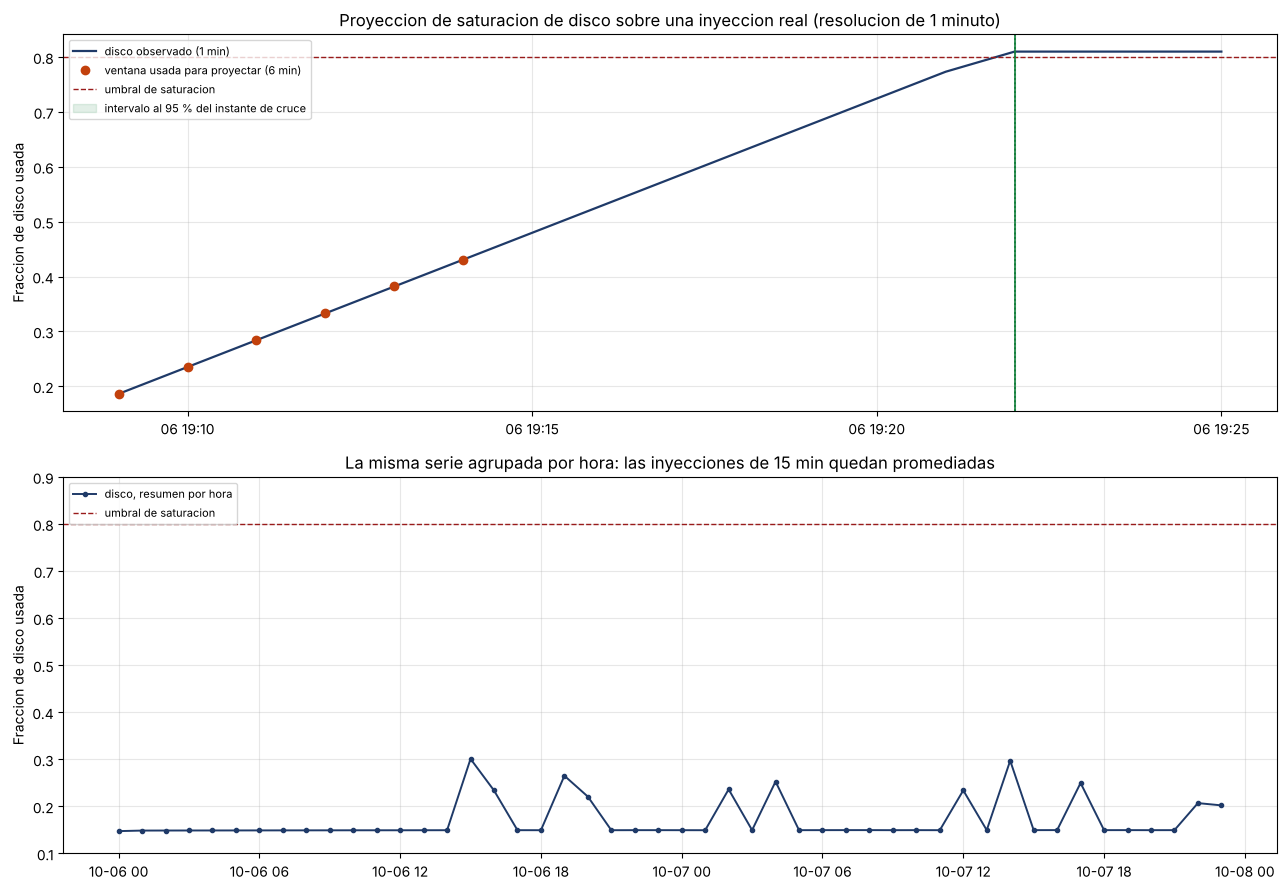

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(13, 9))

# (a) la proyeccion sobre una inyeccion real, a resolucion de minuto
t = [p[0] for p in puntos_ej]
v = [p[1] for p in puntos_ej]
axes[0].plot(t, v, color="#1f3a68", lw=1.6, label="disco observado (1 min)")
usados = puntos_ej[:6]
axes[0].plot([p[0] for p in usados], [p[1] for p in usados], "o", color="#c2410c",
             label="ventana usada para proyectar (6 min)")
axes[0].axhline(0.80, color="#991b1b", ls="--", lw=1, label="umbral de saturacion")
for borde, etiqueta in ((p["mas_pronto"], "mas pronto"), (p["estimado"], "estimado"),
                        (p["mas_tarde"], "mas tarde")):
    axes[0].axvline(borde, color="#15803d", ls=":" if etiqueta != "estimado" else "-", lw=1.2)
axes[0].axvspan(p["mas_pronto"], p["mas_tarde"], color="#15803d", alpha=0.12,
                label="intervalo al 95 % del instante de cruce")
axes[0].set_title("Proyeccion de saturacion de disco sobre una inyeccion real (resolucion de 1 minuto)")
axes[0].set_ylabel("Fraccion de disco usada")
axes[0].legend(fontsize=8, loc="upper left")
axes[0].grid(alpha=0.3)

# (b) la misma inyeccion vista por hora: el fenomeno desaparece
axes[1].plot(por_hora.index, por_hora["disco_used_frac"], color="#1f3a68", lw=1.4,
             marker="o", ms=3, label="disco, resumen por hora")
axes[1].axhline(0.80, color="#991b1b", ls="--", lw=1, label="umbral de saturacion")
axes[1].set_title("La misma serie agrupada por hora: las inyecciones de 15 min quedan promediadas")
axes[1].set_ylabel("Fraccion de disco usada")
axes[1].set_ylim(0.10, 0.90)
axes[1].legend(fontsize=8, loc="upper left")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 8. Reentrenamiento, versión y limitaciones

**Ciclo de reentrenamiento (RF-DET-05).** La proyección de saturación no tiene
modelo persistido: la recta se reajusta en cada ciclo sobre la ventana reciente,
que es lo que permite que la proyección se retire cuando la tendencia se aplana
(HU-28). Lo que se versiona es el método y sus parámetros —ventana, nivel de
confianza, umbral por recurso—, y es lo que se guarda abajo y viaja con cada
proyección. El pronóstico horario de CPU y memoria sí tiene modelo ajustado: se
reentrena semanalmente mientras la campaña acumule historia, y en cada
reentrenamiento se repite la validación de la sección 6 antes de reemplazar el
modelo en uso.

**Por qué no se guardan los `.pkl`.** La versión anterior guardaba tres objetos
de resultados de `statsmodels` de unos 19 MB cada uno. Son frágiles entre
versiones de la biblioteca y se regeneran ejecutando este cuaderno, así que aquí
solo se guarda la especificación, de unos pocos kilobytes.

**Limitaciones declaradas.**

- La estacionalidad diaria no se puede estimar con dos días de historia. El
  término estacional vuelve cuando la campaña de Azure acumule al menos tres
  ciclos completos, y entonces se revalida con la sección 6.
- La prueba de aceptación de H-035 se evalúa sobre el resumen por minuto, porque
  las inyecciones del laboratorio duran menos que un intervalo horario. Para la
  resolución horaria de RF-DET-04 hace falta, o un crecimiento real de varios
  días, o una inyección de disco gradual de varias horas sin limpieza
  intermedia.
- La proyección está validada para **disco** (7 de 7 inyecciones anticipadas).
  Para **memoria** no: la inyección de memoria es un salto de menos de un minuto
  y el aviso llega después del cruce. H-035 pide los dos recursos, así que esto
  se declara como no demostrado y se corrige con una inyección de memoria
  gradual, no retocando el modelo.
- El intervalo sale casi nulo sobre el relleno del laboratorio porque es
  perfectamente lineal, y colapsa también cuando el umbral ya se cruzó dentro de
  la ventana. Sobre crecimiento con ruido la banda sí se ensancha (sección 5, con
  una serie sintética). Este conjunto no tiene crecimiento real y lento, así que
  el ancho del intervalo en condiciones realistas queda sin caracterizar: es lo
  primero que habrá que medir con la campaña de Azure.
- Una proyección de tendencia avisa de saturaciones que no ocurren cuando el
  crecimiento se detiene por su cuenta. Se reporta junto a los aciertos.

In [10]:
ESPECIFICACION = {
    "metodo": "tendencia-lineal-v1",
    "entregable": "instante de saturacion con intervalo de prediccion",
    "nivel_confianza": NIVEL_CONFIANZA,
    "puntos_minimos": MINIMO_PUNTOS,
    "umbrales_validacion": UMBRALES,
    "resolucion_validacion": "1min",
    "resolucion_produccion": "1h (RF-DET-04)",
    "horas_prueba_pronostico": HORAS_PRUEBA,
    "estacionalidad": "desactivada: se requieren >= 3 ciclos diarios (seccion 2)",
    "datos": str(RUTA),
}
Path("especificacion_proyeccion.json").write_text(json.dumps(ESPECIFICACION, indent=2) + "\n")
print(json.dumps(ESPECIFICACION, indent=2))

{
  "metodo": "tendencia-lineal-v1",
  "entregable": "instante de saturacion con intervalo de prediccion",
  "nivel_confianza": 0.95,
  "puntos_minimos": 4,
  "umbrales_validacion": {
    "disco": 0.7,
    "memoria": 0.65
  },
  "resolucion_validacion": "1min",
  "resolucion_produccion": "1h (RF-DET-04)",
  "horas_prueba_pronostico": 12,
  "estacionalidad": "desactivada: se requieren >= 3 ciclos diarios (seccion 2)",
  "datos": "../Clustering/data.csv"
}
